# Front-of-Package Nutrition Label RCT Analysis (Grummon et al., 2025 Benchmark)

In [1]:
# Step 1: Import Grummon OLS estimation utilities and load the Grummon et al. (2025) FOP nutrition label RCT dataset
import importlib
import matplotlib.pyplot as plt
import pandas as pd
import grummon_ols

importlib.reload(grummon_ols)
from grummon_ols import (
    evaluate_grummon_metrics,
    fit_grummon_ols,
    load_all_model_regressions,
    load_grummon_rct,
    plot_grummon_error_comparison,
    subsample_grummon_participants,
)

raw_df = load_grummon_rct()
print(
    f"Loaded {len(raw_df):,} three-option product choice tasks across {raw_df['CASEID'].nunique():,} participants "
    f"and {raw_df['arm'].nunique()} randomized FOP labeling arms (d=5 treatment effects vs. 'Positive')"
)

Loaded 33,798 three-option product choice tasks across 5,633 participants and 6 randomized FOP labeling arms (d=5 treatment effects vs. 'Positive')


In [2]:
# Step 2: Fit full-sample human ground-truth HC1 OLS regression (beta*, N = 5,633 participants, 33,798 tasks)
human_ols_df = fit_grummon_ols(raw_df)
beta_star = human_ols_df["beta"].copy()

# Step 3: Subsample 200 participants (1,200 choice tasks, seed=42) and fit Human Subsample Baseline HC1 OLS (beta_sub)
N_LLM_PARTICIPANTS = 200
SUBSAMPLE_SEED = 42

sub_df = subsample_grummon_participants(raw_df, n_participants=N_LLM_PARTICIPANTS, seed=SUBSAMPLE_SEED)
human_sub_ols_df = fit_grummon_ols(sub_df)
beta_human_sub = human_sub_ols_df["beta"].copy()
human_sub_metrics = evaluate_grummon_metrics(beta_human_sub, beta_star)

print(
    f"Human Subsample Baseline (N={sub_df['CASEID'].nunique()}, n={len(sub_df):,} tasks) vs. Full Human (beta*): "
    f"MAPE = {human_sub_metrics['MAPE (%)']:.2f}%, MSE = {human_sub_metrics['MSE']:.4f}"
)
human_sub_ols_df.assign(full_human_beta=beta_star, diff=beta_human_sub - beta_star).round(4)

Human Subsample Baseline (N=200, n=1,200 tasks) vs. Full Human (beta*): MAPE = 22.66%, MSE = 0.0016


,arm,beta,se,z,p_value,full_human_beta,diff
label,,,,,,,
Nutrition Info label (vs. Positive),NutritionInfo,0.1031,0.0759,1.3585,0.1743,0.1844,-0.0813
High In warning label (vs. Positive),HighIn,0.0365,0.0692,0.5267,0.5984,0.0541,-0.0176
Positive + Nutrition Info (vs. Positive),Positive+NutritionInfo,0.2031,0.0655,3.1006,0.0019,0.1788,0.0243
Positive + High In (vs. Positive),Positive+HighIn,0.1317,0.0671,1.9618,0.0498,0.1194,0.0123
Spectrum 1-to-5 star label (vs. Positive),Spectrum,0.1222,0.0696,1.7565,0.0790,0.1083,0.0139


# Kev Model Predictions & OLS Regressions

In [18]:
# Step 4: Dynamically discover all collected Kev Grummon JSONL datasets in data/ and fit HC1 OLS regressions
importlib.reload(grummon_ols)
from grummon_ols import load_all_model_regressions, plot_grummon_error_comparison

model_ols_dfs = load_all_model_regressions(sub_df, kev_data_dir="data")
print(f"Dynamically loaded and fitted {len(model_ols_dfs)} Kev model datasets:")
for name in model_ols_dfs:
    print(" -", name)

Dynamically loaded and fitted 8 Kev model datasets:
 - jaredpalmer/kev-0.8b (Respondent Persona, N=200, n=1200)
 - jaredpalmer/kev-0.8b (Random Persona, N=200, n=1200)
 - kev-0.8b-resp-issp+twin2k-grouped/best (Respondent Persona, N=200, n=1200)
 - kev-0.8b-resp-issp+twin2k-grouped/best (Random Persona, N=200, n=1200)
 - jaredpalmer/kev-9b (Respondent Persona, N=200, n=1200)
 - jaredpalmer/kev-9b (Random Persona, N=200, n=1200)
 - kev-9b-resp-issp+twin2k-grouped-newvalid/best (Respondent Persona, N=200, n=1200)
 - kev-9b-resp-issp+twin2k-grouped-newvalid/best (Random Persona, N=200, n=1200)


In [19]:
# Step 5: Compare all Kev estimators against Full Human (beta*) and Same Human Subsample (beta_sub) using MAPE & MSE
estimators_beta = {
    f"Human Subsample Baseline (N={sub_df['CASEID'].nunique()}, n={len(sub_df)})": beta_human_sub,
    **{name: df_m["beta"] for name, df_m in model_ols_dfs.items()},
}

comparison_rows = {}
for name, b_hat in estimators_beta.items():
    vs_full = evaluate_grummon_metrics(b_hat, beta_star)
    vs_sub = evaluate_grummon_metrics(b_hat, beta_human_sub)
    comparison_rows[name] = {
        "MAPE vs. Full Human (%)": vs_full["MAPE (%)"],
        "MSE vs. Full Human": vs_full["MSE"],
        "MAPE vs. Human Subsample (%)": vs_sub["MAPE (%)"],
        "MSE vs. Human Subsample": vs_sub["MSE"],
    }

comparison_metrics_df = pd.DataFrame(comparison_rows).T.sort_values("MSE vs. Full Human", ascending=True)
print("=== Error Metrics (MAPE & MSE) on Grummon RCT vs. Full Human (beta*) and Same Human Subsample (sorted best to worst on MSE) ===")
display(comparison_metrics_df.round(4))

coef_comparison_df = pd.DataFrame({
    "Full Human (beta*, N=5633)": beta_star,
    **estimators_beta,
})
# display(coef_comparison_df.round(4))

=== Error Metrics (MAPE & MSE) on Grummon RCT vs. Full Human (beta*) and Same Human Subsample (sorted best to worst on MSE) ===


,MAPE vs. Full Human (%),MSE vs. Full Human,MAPE vs. Human Subsample (%),MSE vs. Human Subsample
"Human Subsample Baseline (N=200, n=1200)",22.6629,0.0016,0.0000,0.0000
"kev-0.8b-resp-issp+twin2k-grouped/best (Random Persona, N=200, n=1200)",50.2678,0.0036,70.3816,0.0049
"kev-0.8b-resp-issp+twin2k-grouped/best (Respondent Persona, N=200, n=1200)",53.1900,0.0049,64.8194,0.0057
"jaredpalmer/kev-9b (Respondent Persona, N=200, n=1200)",62.7936,0.0051,65.9205,0.0062
"kev-9b-resp-issp+twin2k-grouped-newvalid/best (Respondent Persona, N=200, n=1200)",70.5223,0.0056,88.8376,0.0065
"kev-9b-resp-issp+twin2k-grouped-newvalid/best (Random Persona, N=200, n=1200)",66.1606,0.0056,65.7132,0.0059
"jaredpalmer/kev-9b (Random Persona, N=200, n=1200)",64.8684,0.0069,65.6734,0.0086
"jaredpalmer/kev-0.8b (Random Persona, N=200, n=1200)",86.4099,0.0112,108.0306,0.0113
"jaredpalmer/kev-0.8b (Respondent Persona, N=200, n=1200)",81.5422,0.0116,101.7408,0.0108


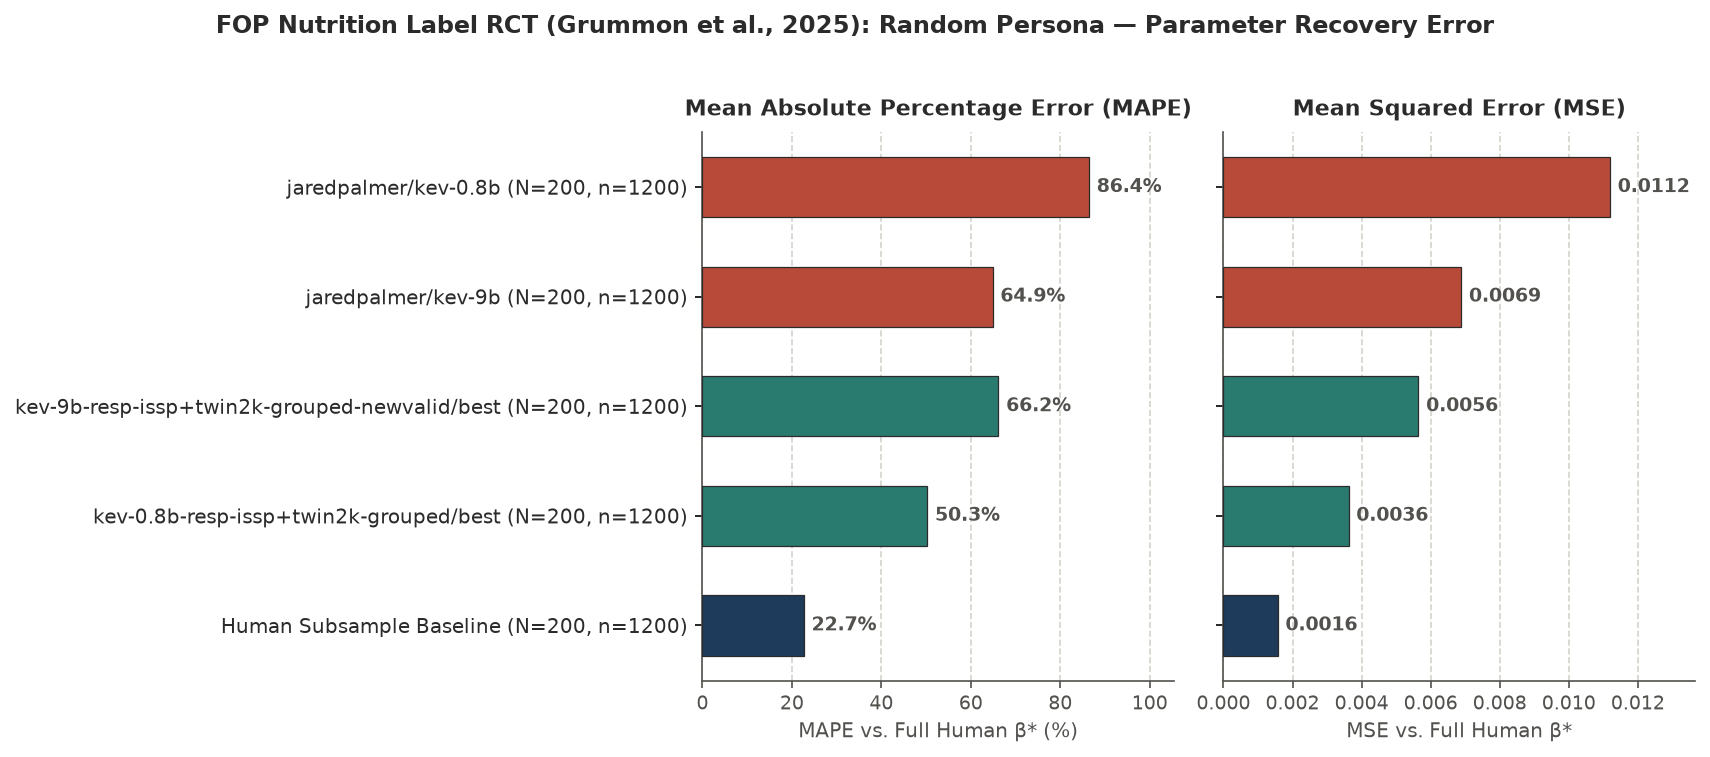

In [20]:
# Step 6a: Plot Random Persona Kev models (plus Human Subsample Baseline) sorted best-to-worst on MSE vs. Full Human (beta*)
fig_random = plot_grummon_error_comparison(
    comparison_metrics_df,
    palette="nature",
    persona_filter="Random Persona",
    sort_by="MSE vs. Full Human",
)
plt.show()

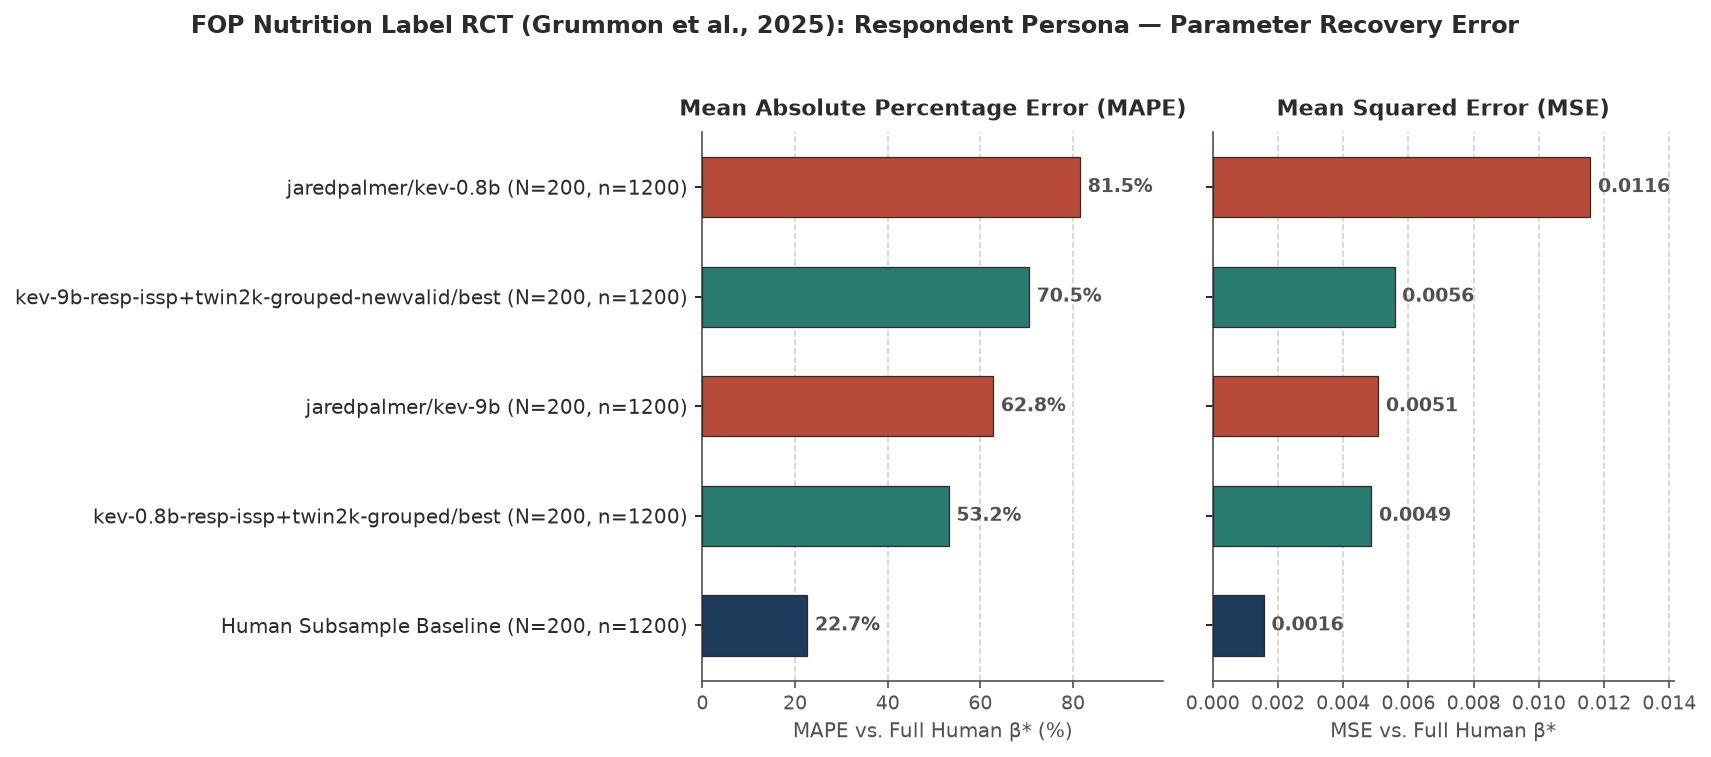

In [21]:
# Step 6b: Plot Respondent Persona Kev models (plus Human Subsample Baseline) sorted best-to-worst on MSE vs. Full Human (beta*)
fig_persona = plot_grummon_error_comparison(
    comparison_metrics_df,
    palette="nature",
    persona_filter="Respondent Persona",
    sort_by="MSE vs. Full Human",
)
plt.show()